# Experiment 6 · Hold-period drift in v2_catch, 20 seeds

**Date:** 2026-11-08 · **Agents:** `v2_catch_s1`–`s20` (v2), `baseline_s1`–`s8` (v1 reference) · **Status:** 20 seeds

## Question
Experiment 5 (3 seeds per arm) chose `v2_catch` because it had no centre pull, no target
pull and almost no pre-go drift. **Does that hold across 20 seeds**, and how does the
remaining drift compare with v1?

`v2_catch` = random start in ±0.5 with a visible start marker, 40 ms sensory delay, 80 ms
cue delay, 20% catch trials, abort at 0.15. 4M steps per seed.

## Measures (all noiseless plant, mean action)
1. **Competence gate:** success on 512 training-distribution trials, from the centre and
   from random starts in ±0.5. Floor 0.90.
2. **Pre-go drift in task trials** (same 512 trials): displacement and velocity on the step
   before the go cue, signed so + = towards the first target; and the unsigned size |drift|.
3. **Centre pull and target pull:** hold probe as in Experiment 3, inside the trained range:
   starts ±0.4, targets at offsets ±0.2/±0.4, **1.5 s hold** (the longest catch trial),
   abort off. Fit v(0.3 s) = b_centre·x₀ + b_target·(T − x₀). Also the decisive *outward*
   conditions (target further from the centre than the start).
4. **Drift against target distance:** Experiment 4 found that far targets drive the
   strongest drift in v1. Starts {−0.4, 0, +0.4}, targets at every offset in ±0.2…±1.2
   that stays inside ±0.9, 1.5 s hold. Displacement towards the target after 1 s and 1.5 s.

v1 was only ever trained from x = 0 with holds ≤ 1 s, so its numbers in 2–4 include
conditions outside its training; they are a reference, not a fair contest.

In [1]:
from exp_tools import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

use_style()
pd.set_option("display.precision", 4)
V2 = [f"v2_catch_s{s}" for s in range(1, 21)]
V1 = [f"baseline_s{s}" for s in range(1, 9)]
GROUP = {**{r: "v1" for r in V1}, **{r: "v2_catch" for r in V2}}
COL = {"v1": INK_SOFT, "v2_catch": AQUA}
missing = [r for r in V1 + V2 if not (RUNS / r / "checkpoint.pt").exists()]
print("missing checkpoints:", missing or "none")

missing checkpoints: none


## 1–2 · Competence and pre-go drift in task trials

In [2]:
rows = []
for r in V1 + V2:
    c0 = competence(RUNS / r)
    c5 = competence(RUNS / r, start_range=0.5)
    rows.append({"run": r, "group": GROUP[r],
                 "succ_centre": c0["success_rate"], "succ_random": c5["success_rate"],
                 "fs_random": c5["false_start_rate"],
                 "drift_centre": c0["drift_x_to_target"], "drift_abs_centre": c0["drift_abs"],
                 "drift_v_centre": c0["drift_v_to_target"],
                 "drift_random": c5["drift_x_to_target"], "drift_abs_random": c5["drift_abs"],
                 "drift_v_random": c5["drift_v_to_target"]})
task = pd.DataFrame(rows)
task["competent"] = (task.succ_centre >= 0.9) & (task.succ_random >= 0.9)
print(task.groupby("group").competent.agg(["sum", "size"]))
task.groupby("group")[["succ_centre", "succ_random", "fs_random", "drift_centre",
                       "drift_abs_centre", "drift_v_centre", "drift_random",
                       "drift_abs_random"]].agg(["mean", "std"]).T

          sum  size
group              
v1          8     8
v2_catch   19    20


group                      v1  v2_catch
succ_centre      mean  0.9988    0.9865
                 std   0.0021    0.0548
succ_random      mean  0.9731    0.9862
                 std   0.0171    0.0543
fs_random        mean  0.0247    0.0000
                 std   0.0171    0.0000
drift_centre     mean  0.0055   -0.0025
                 std   0.0069    0.0034
drift_abs_centre mean  0.0125    0.0102
                 std   0.0040    0.0038
drift_v_centre   mean  0.0177    0.0033
                 std   0.0145    0.0035
drift_random     mean  0.0223   -0.0025
                 std   0.0083    0.0036
drift_abs_random mean  0.0321    0.0104
                 std   0.0114    0.0038

In [3]:
task.set_index("run")

,group,succ_centre,succ_random,fs_random,drift_centre,drift_abs_centre,drift_v_centre,drift_random,drift_abs_random,drift_v_random,competent
run,,,,,,,,,,,
baseline_s1,v1,0.9980,0.9414,0.0566,0.0139,0.0162,0.0358,0.0383,0.0523,0.0838,True
baseline_s2,v1,1.0000,0.9590,0.0391,-0.0010,0.0094,0.0049,0.0229,0.0377,0.0496,True
baseline_s3,v1,0.9941,0.9805,0.0176,0.0138,0.0180,0.0316,0.0225,0.0260,0.0500,True
baseline_s4,v1,0.9980,0.9824,0.0117,-0.0010,0.0128,0.0021,0.0193,0.0291,0.0416,True
baseline_s5,v1,1.0000,0.9629,0.0352,0.0079,0.0136,0.0249,0.0295,0.0429,0.0647,True
baseline_s6,v1,1.0000,0.9922,0.0078,-0.0020,0.0071,0.0040,0.0177,0.0292,0.0381,True
baseline_s7,v1,1.0000,0.9863,0.0137,0.0014,0.0078,0.0067,0.0122,0.0188,0.0270,True
baseline_s8,v1,1.0000,0.9805,0.0156,0.0111,0.0155,0.0313,0.0158,0.0209,0.0392,True
v2_catch_s1,v2_catch,1.0000,1.0000,0.0000,-0.0001,0.0142,-0.0002,0.0004,0.0136,-0.0006,True


## 3 · Centre pull and target pull (hold probe, 1.5 s, inside the trained range)

In [4]:
hp_rows, hp_all = [], []
for r in V1 + V2:
    df, traj, dt, hold = hold_probe(RUNS / r, starts=np.round(np.arange(-0.4, 0.41, 0.2), 2),
                                    hold_s=1.5)
    df["group"] = GROUP[r]
    hp_all.append(df)
    f = drift_fit(df)
    out = df[df.side == "outward"]
    hp_rows.append({"run": r, "group": GROUP[r], **f,
                    "outward_to_centre": out.drift_to_centre.mean(),
                    "outward_to_target": out.drift_to_target.mean(),
                    "max_abs_disp_1.5s": (df.x_end - df.x0).abs().max(),
                    "mean_abs_disp_1.5s": (df.x_end - df.x0).abs().mean()})
pull = pd.DataFrame(hp_rows)
hp_all = pd.concat(hp_all, ignore_index=True)
pull.groupby("group")[["b_centre", "b_target", "R2", "outward_to_centre", "outward_to_target",
                       "mean_abs_disp_1.5s", "max_abs_disp_1.5s"]].agg(["mean", "std", "min", "max"]).T

group                        v1  v2_catch
b_centre           mean -0.1652    0.0018
                   std   0.1423    0.0168
                   min  -0.4005   -0.0224
                   max   0.0507    0.0345
b_target           mean  0.0345    0.0053
                   std   0.0391    0.0395
                   min  -0.0156   -0.0457
                   max   0.0816    0.0963
R2                 mean  0.9527    0.9435
                   std   0.0656    0.0669
                   min   0.8068    0.6969
                   max   0.9982    0.9966
outward_to_centre  mean  0.8125    0.4813
                   std   0.3273    0.3015
                   min   0.1250    0.0000
                   max   1.0000    1.0000
outward_to_target  mean  0.1875    0.5188
                   std   0.3273    0.3015
                   min   0.0000    0.0000
                   max   0.8750    1.0000
mean_abs_disp_1.5s mean  0.0672    0.0138
                   std   0.0312    0.0080
                   min   0.0233    0.0019
                   max   0.1197    0.0324
max_abs_disp_1.5s  mean  0.1453    0.0199
                   std   0.0680    0.0115
                   min   0.0501    0.0043
                   max   0.2497    0.0442

In [5]:
pull.set_index("run")

,group,b_centre,b_target,c,R2,outward_to_centre,outward_to_target,max_abs_disp_1.5s,mean_abs_disp_1.5s
run,,,,,,,,,
baseline_s1,v1,-0.4005,0.0794,-0.0095,0.9982,1.000,0.000,0.2497,0.1197
baseline_s2,v1,-0.1954,-0.0139,0.0111,0.9854,1.000,0.000,0.1476,0.0720
baseline_s3,v1,-0.0676,0.0816,-0.0299,0.8068,0.500,0.500,0.0866,0.0482
baseline_s4,v1,-0.1582,0.0641,-0.0098,0.9785,0.875,0.125,0.1275,0.0579
baseline_s5,v1,-0.2927,0.0298,0.0215,0.9899,1.000,0.000,0.2362,0.1025
baseline_s6,v1,-0.2009,-0.0156,0.0085,0.9948,1.000,0.000,0.1327,0.0667
baseline_s7,v1,-0.0572,0.0090,0.0057,0.9101,1.000,0.000,0.0501,0.0233
baseline_s8,v1,0.0507,0.0414,-0.0204,0.9576,0.125,0.875,0.1318,0.0473
v2_catch_s1,v2_catch,0.0100,-0.0144,-0.0544,0.9447,0.500,0.500,0.0221,0.0207


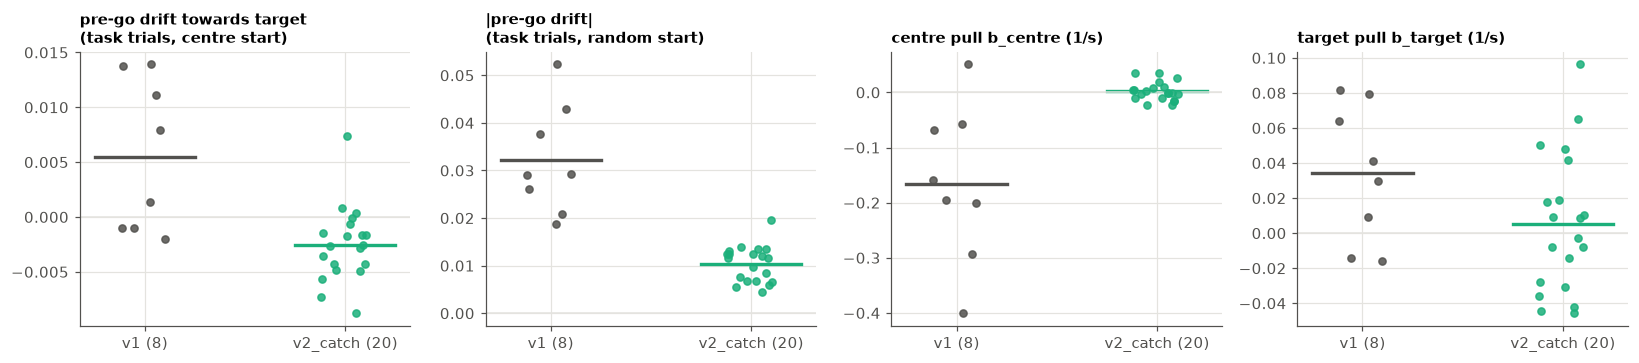

In [6]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
measures = [("drift_centre", task, "pre-go drift towards target\n(task trials, centre start)"),
            ("drift_abs_random", task, "|pre-go drift|\n(task trials, random start)"),
            ("b_centre", pull, "centre pull b_centre (1/s)"),
            ("b_target", pull, "target pull b_target (1/s)")]
for ax, (col, d, title) in zip(axs, measures):
    for j, g in enumerate(["v1", "v2_catch"]):
        y = d[d.group == g][col].to_numpy()
        ax.scatter(j + np.random.default_rng(0).uniform(-0.12, 0.12, len(y)), y,
                   color=COL[g], s=22, zorder=3, alpha=0.85)
        ax.plot([j - 0.25, j + 0.25], [np.mean(y)] * 2, color=COL[g], lw=2.2)
    ax.axhline(0, color=GRID, lw=1)
    ax.set_xticks([0, 1], ["v1 (8)", "v2_catch (20)"])
    ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.show()

### The outward conditions, seed by seed

Target further from the centre than the start. Fraction of conditions where the mass drifts towards the centre (centre pull) or towards the target (target pull). With no pull at all, drifts are tiny and their direction is close to random.

In [7]:
pull.set_index("run")[["group", "outward_to_centre", "outward_to_target", "b_centre", "b_target"]]

,group,outward_to_centre,outward_to_target,b_centre,b_target
run,,,,,
baseline_s1,v1,1.000,0.000,-0.4005,0.0794
baseline_s2,v1,1.000,0.000,-0.1954,-0.0139
baseline_s3,v1,0.500,0.500,-0.0676,0.0816
baseline_s4,v1,0.875,0.125,-0.1582,0.0641
baseline_s5,v1,1.000,0.000,-0.2927,0.0298
baseline_s6,v1,1.000,0.000,-0.2009,-0.0156
baseline_s7,v1,1.000,0.000,-0.0572,0.0090
baseline_s8,v1,0.125,0.875,0.0507,0.0414
v2_catch_s1,v2_catch,0.500,0.500,0.0100,-0.0144


## 4 · Drift against target distance (1.5 s hold, abort off)

In [8]:
dist_rows = []
offs = tuple(np.round(np.concatenate([-np.arange(1.2, 0.19, -0.2), np.arange(0.2, 1.21, 0.2)]), 2))
for r in V1 + V2:
    df, traj, dt, hold = hold_probe(RUNS / r, starts=np.array([-0.4, 0.0, 0.4]),
                                    offsets=offs, hold_s=1.5)
    sgn = np.sign(df.offset)
    df["to_target_1s"] = sgn * (df.x_1s - df.x0)
    df["to_target_1.5s"] = sgn * (df.x_end - df.x0)
    df["dist"] = df.offset.abs().round(2)
    df["group"], df["run2"] = GROUP[r], r
    dist_rows.append(df)
dist = pd.concat(dist_rows, ignore_index=True)
tab = dist.groupby(["group", "dist"])[["to_target_1s", "to_target_1.5s"]].mean().unstack("group")
tab

to_target_1s          to_target_1.5s         
group           v1 v2_catch             v1 v2_catch
dist                                               
0.2         0.0095  -0.0003         0.0147   0.0003
0.4         0.0139  -0.0008         0.0229   0.0003
0.6         0.0446  -0.0021         0.0696  -0.0008
0.8         0.0524  -0.0023         0.0820  -0.0007
1.0         0.1045  -0.0026         0.1543  -0.0008
1.2         0.1447  -0.0010         0.2064   0.0020

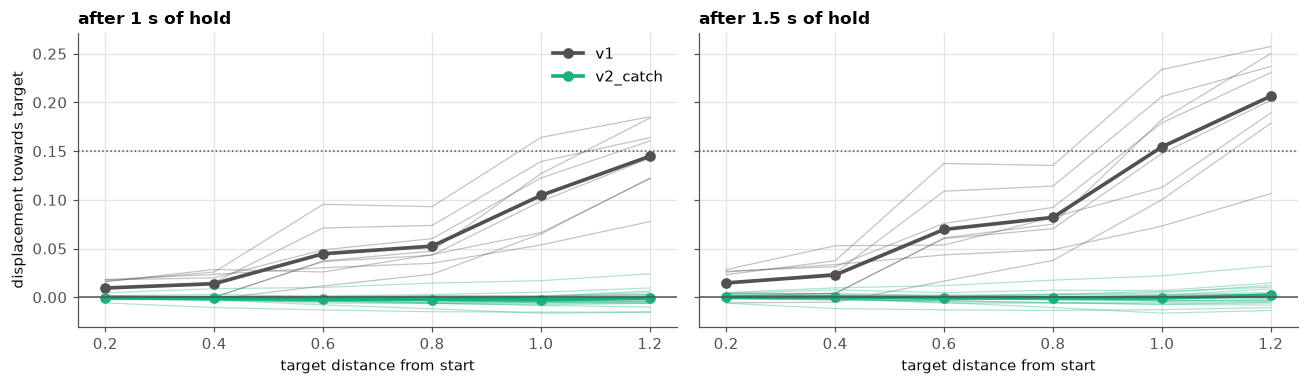

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, col, title in zip(axs, ["to_target_1s", "to_target_1.5s"],
                          ["after 1 s of hold", "after 1.5 s of hold"]):
    for g in ["v1", "v2_catch"]:
        per_run = dist[dist.group == g].groupby(["run2", "dist"])[col].mean().unstack("dist")
        for _, row in per_run.iterrows():
            ax.plot(row.index, row.values, color=COL[g], lw=0.8, alpha=0.35)
        ax.plot(per_run.columns, per_run.mean().values, "o-", color=COL[g], lw=2.4, label=g)
    ax.axhline(0, color=INK_SOFT, lw=1)
    ax.axhline(0.15, color=INK_SOFT, ls=":", lw=1)
    ax.set_xlabel("target distance from start"); ax.set_title(title)
axs[0].set_ylabel("displacement towards target")
axs[0].legend()
plt.tight_layout(); plt.show()

In [10]:
# Would any trained-range hold end in a false start? (|x - x0| > 0.15 within 1.5 s)
fs_hold = dist.assign(fs=(dist["to_target_1.5s"].abs() > 0.15) | (dist["to_target_1s"].abs() > 0.15))
fs_hold.groupby(["group", "dist"]).fs.mean().unstack("group")

group,v1,v2_catch
dist,,
0.2,0.1042,0.0
0.4,0.1042,0.0
0.6,0.0938,0.0
0.8,0.1562,0.0
1.0,0.5625,0.0
1.2,0.8125,0.0


In [11]:
task.to_csv("exp06_task_drift.csv", index=False)
pull.to_csv("exp06_pull_fits.csv", index=False)
dist.to_csv("exp06_drift_vs_distance.csv", index=False)
print("saved")

saved


## Conclusion

**Across 20 seeds, v2_catch has no directed hold drift: no centre pull, no target pull, and no
drift that grows with target distance. What remains is a small, undirected movement of about
0.01, a fifth of the target tolerance.**

**Competence.** 19 of 20 seeds pass the 0.90 floor, from the centre and from random starts.
**`v2_catch_s7` fails (0.75)** and is excluded from every claim below. It ended training at
0.735 success, so it is a training failure, not an evaluation artefact. Numbers below are
for the 19 competent seeds.

| measure | v1 (8 seeds) | v2_catch (19 seeds) |
| --- | --- | --- |
| false starts from random starts | 2.5% | **0%** |
| centre pull b_centre (1/s) | −0.17 (−0.40 to +0.05) | **+0.002** (−0.022 to +0.035) |
| hold-probe displacement after 1.5 s, mean / max over seeds | 0.067 / 0.25 | **0.014 / 0.044** |
| displacement towards a target 1.2 away, after 1.5 s | 0.21 | **0.002** |
| hold-probe conditions ending in a false start, 1.2-away targets | 81% | **0%** |
| pre-go drift towards target, task trials, centre start | +0.0055 | **−0.0026** |
| \|pre-go drift\|, task trials, random start | 0.032 | **0.011** |

1. **The centre pull is gone in every seed.** All 19 b_centre values sit within ±0.035 of
   zero; v1 ranges down to −0.40.
2. **There is no systematic target pull.** b_target averages +0.003 with seeds on both sides
   (−0.046 to +0.096). In the decisive outward conditions, the direction of drift is a
   coin flip on average (48% towards the centre). These fits describe *very small early
   velocities*: no v2 seed moves more than 0.044 in a 1.5 s hold (v1: up to 0.25). So the
   per-seed b values here are noise-level and should not be read as pulls.
3. **The far-target failure from Experiment 4 is gone.** In v1, the drift towards the target
   grows with target distance and crosses the false-start line in 81% of 1.2-away
   conditions. In v2_catch it stays at about 0 for every distance, in every seed.
4. **A small, consistent detail:** in centre-start task trials, 16 of 19 seeds end the hold
   very slightly *away* from the target (mean −0.0026, about 5% of the tolerance), while the
   velocity at the go step points slightly towards it in 14 of 19. This looks like a tiny
   wind-up before the cue, but it is far too small to matter behaviourally. Neural analyses
   of the hold can control for it.
5. **The residual |drift| (~0.01) is about the size v1 already had from the centre start
   (0.013).** v2 did not make the mass motionless. It removed the *directed* part (centre and
   target), which is what made v1's hold period ambiguous.

**Bottom line:** the 19 competent `v2_catch` seeds have a clean hold period and can be used
for analyses of preparation and the go cue. Exclude `v2_catch_s7`.

*Limits: noiseless plant, mean action; hold probe within the trained start range (±0.4)
and the longest trained hold (1.5 s); catch trials make the hold relevant only up to 1.5 s.
Lookahead and RT were measured on the 3 pilot seeds only (Experiment 5) and have not yet
been re-measured on all 20.*